# Análisis de calidad del pipeline: RAW → Bronze → Silver → Gold → OBT

| | |
|---|---|
| **Curso** | MSDS 6003 Ciencia de Datos (USFQ) |
| **Entrega** | PSet 3, análisis de calidad del pipeline (paso Q1 de `plan.txt`) |
| **Autor** | Allan Paul Gómez Ehmig (00351916) |
| **Datos** | base `PORTAFOLIO_P3` en Snowflake (esquemas RAW, BRONZE, SILVER, GOLD, CALIDAD, OBT) |
| **Código que se analiza** | `pipeline/kestra` (RAW), `pipeline/dbt` (Bronze, Silver, Gold, CALIDAD), `pipeline/spark/jobs/construir_obt.py` (OBT) |
| **Operación** | solo `SELECT`; el notebook no escribe en la base |

**Objetivo.** Medir, para cada columna de cada capa, qué porcentaje de valores falta, cuál viola una regla
de dominio y cuál fue imputado; seguir las filas de una capa a la siguiente; y describir qué operación
hace cada nivel. Es la evidencia de la limpieza del pipeline que usa el EDA del PSet 3.

**Qué pide el enunciado (CD_PSet_3.pdf, EDA).** Tamaño, tipos y faltantes por columna; valores atípicos
(IQR y z ≥ 3); y al menos tres hallazgos con evidencia y consecuencia. Este notebook cubre esa parte
para todas las capas, no solo para la OBT.

**Cómo correrlo.** *Restart + Run All* desde `pipeline/docs/calidad/`, con el entorno de `psets/pset-03`
(`uv run jupyter lab` o el kernel de `.venv`). Variable `MOTOR`:
- `snowflake` (por defecto si existe `pipeline/.env`): lee `PORTAFOLIO_P3` con las credenciales de `.env`.
- `duckdb`: usa la muestra de `pipeline/pruebas_locales/` (necesita `uv sync --group analisis`); sirve
  para probar el notebook sin Snowflake, no para reportar números.

No correrlo con MLflow levantado al mismo tiempo que Kestra o Spark.

## Definiciones

| Medida | Definición | Notas |
|---|---|---|
| **Faltante** | `NULL`, o texto vacío o de solo espacios | `false` no es faltante. En Silver y Gold un día imputado deja nulos a propósito los precios sin ajustar y el volumen (no se observaron): se cuentan aparte como *faltante por imputación*. |
| **Inválido** | el valor viola una regla de dominio de la columna (precio ≤ 0, volumen < 0, mes fuera de 1–12, retorno simple < −100 %, fecha futura, código de bolsa desconocido, …) | Las reglas son las de `scripts/diagnosticar_calidad.py`, extendidas a las columnas de F1. **Sin regla = "no evaluado"**, que no significa 0 %. |
| **Inconsistente** | dos columnas de la misma fila se contradicen (máximo < mínimo, cierre fuera del rango del día) | Se mide por tabla. |
| **Imputado** | el valor no se observó y el pipeline lo rellenó | Silver: *forward-fill* del log-precio ajustado (cierre y apertura) en huecos de hasta 5 días; ^IRX rellenada con el último valor. Las diferencias y retornos de ese día se *derivan* del valor imputado. |
| **Atípico** | valor válido pero extremo (\|retorno log diario\| > 0,4; Tukey IQR; \|z\| ≥ 3) | No se borra: se marca (`es_retorno_extremo`) y se decide en el modelado. |

In [1]:
# Configuración: motor (Snowflake o DuckDB), conexión de solo lectura y función consulta().
# Prompt usado (IA): "fortalece el análisis del proceso de limpieza con un reporte de las columnas en los
# distintos niveles: % de faltantes, inválidos e imputados, y un informe de las operaciones de cada nivel".
import os, re, json, base64, time
from datetime import datetime, timezone
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_rows', 400); pd.set_option('display.max_columns', 40); pd.set_option('display.width', 200)

def raiz_pipeline():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / 'dbt').is_dir() and (p / 'spark').is_dir():
            return p
        if (p / 'pipeline' / 'dbt').is_dir():
            return p / 'pipeline'
    raise FileNotFoundError('Abrir el notebook desde psets/pset-03/pipeline/docs/calidad')
R = raiz_pipeline()
ENV = {}
if (R / '.env').exists():
    for linea in (R / '.env').read_text().splitlines():
        if '=' in linea and not linea.lstrip().startswith('#'):
            k, _, v = linea.partition('='); ENV[k.strip()] = v.strip()
ENV = {**ENV, **{k: v for k, v in os.environ.items() if k.startswith('SNOWFLAKE_')}}
MOTOR = os.environ.get('MOTOR') or ('snowflake' if ENV.get('SNOWFLAKE_ACCOUNT') else 'duckdb')
CAPAS = ['RAW', 'BRONZE', 'SILVER', 'GOLD', 'CALIDAD', 'OBT']
CONSULTAS = []   # SQL ejecutado, para la evidencia

if MOTOR == 'snowflake':
    import snowflake.connector
    con = snowflake.connector.connect(
        account=ENV['SNOWFLAKE_ACCOUNT'], user=ENV['SNOWFLAKE_USER'],
        private_key=base64.b64decode(ENV['SNOWFLAKE_PRIVATE_KEY']), role=ENV.get('SNOWFLAKE_ROLE'),
        warehouse=ENV.get('SNOWFLAKE_WAREHOUSE'), database=ENV.get('SNOWFLAKE_DATABASE', 'PORTAFOLIO_P3'),
        session_parameters={'QUERY_TAG': 'pset3_analisis_calidad', 'TIMEZONE': 'UTC',
                            'STATEMENT_TIMEOUT_IN_SECONDS': 600})
    BASE = ENV.get('SNOWFLAKE_DATABASE', 'PORTAFOLIO_P3')
    def _ejecutar(sql):
        with con.cursor() as cur:
            cur.execute(sql)
            try:
                df = cur.fetch_pandas_all()
            except Exception:
                df = pd.DataFrame(cur.fetchall(), columns=[c[0] for c in cur.description])
        return df
    SQL_COLUMNAS = f"""select table_schema, table_name, column_name, data_type, ordinal_position
                       from {BASE}.information_schema.columns
                       where table_schema in ({','.join("'" + c + "'" for c in CAPAS)})"""
else:
    import duckdb
    local = R / 'pruebas_locales'
    con = duckdb.connect()
    con.execute(f"ATTACH '{local / 'portafolio_local.duckdb'}' AS fuente (READ_ONLY)")
    for capa in CAPAS:
        con.execute(f'CREATE SCHEMA IF NOT EXISTS {capa}')
    for s, t in con.execute("select table_schema, table_name from information_schema.tables "
                            "where table_catalog='fuente'").fetchall():
        con.execute(f'CREATE VIEW {s.upper()}.{t.upper()} AS SELECT * FROM fuente."{s}"."{t}"')
    for t in ['obt_accion_mes', 'obt_accion_dia', 'validacion_obt']:
        if (local / 'salida' / t).is_dir():
            con.execute(f"CREATE VIEW OBT.{t.upper()} AS SELECT * FROM read_parquet('{local / 'salida' / t}/*.parquet')")
    BASE = 'muestra DuckDB (pruebas_locales)'
    def _ejecutar(sql):
        return con.execute(sql).df()
    SQL_COLUMNAS = """select upper(table_schema) table_schema, upper(table_name) table_name, column_name,
                             data_type, ordinal_position
                      from information_schema.columns where table_catalog = current_database()"""

def consulta(sql):
    t0 = time.perf_counter(); df = _ejecutar(sql)
    df.columns = [c.lower() for c in df.columns]
    CONSULTAS.append({'sql': ' '.join(sql.split()), 'segundos': round(time.perf_counter() - t0, 2), 'filas': len(df)})
    return df

INICIO = datetime.now(timezone.utc)
print(f'Motor: {MOTOR} | base: {BASE} | inicio UTC: {INICIO:%Y-%m-%d %H:%M}')
if MOTOR != 'snowflake':
    print('AVISO: muestra local; los numeros sirven para probar el notebook, no para el memo.')

/Users/paulehmig/Documents/Personal/USFQ/MaestriaDataScience/src/MSDS_6003/data-science-end-to-end-work/psets/pset-03/.venv/lib/python3.11/site-packages/snowflake/connector/connection/_connection.py:137: FutureWarning: enable_server_session_keep_alive_auto_detection was not set and defaults to True. In a future version, the default will change to None. Please provide an explicit value: True = check for running async queries before logout (queries are preserved); False/None = always send logout on close (async queries may be terminated by server). Logout behavior can also be overridden with server_session_keep_alive. See the connection parameter docs for more info.
  options = self.config.to_proto_options(


Motor: snowflake | base: PORTAFOLIO_P3 | inicio UTC: 2026-11-18 04:48


## 1. Inventario de tablas y columnas por capa

Qué tablas existen en cada esquema, cuántas columnas y filas tienen y de qué tipo son.

In [2]:
# Inventario: columnas de information_schema y filas por tabla (count(*)).
col = consulta(SQL_COLUMNAS)
col['table_schema'] = col.table_schema.str.upper(); col['table_name'] = col.table_name.str.upper()
col['columna'] = col.column_name.str.upper()
def familia(tipo):
    t = str(tipo).upper()
    if any(x in t for x in ('CHAR', 'TEXT', 'STRING')): return 'texto'
    if 'BOOL' in t: return 'booleano'
    if 'TIMESTAMP' in t: return 'fecha y hora'
    if 'DATE' in t: return 'fecha'
    if any(x in t for x in ('INT', 'NUMBER', 'DECIMAL', 'FLOAT', 'DOUBLE', 'REAL', 'NUMERIC')): return 'numero'
    return t.lower()
col['tipo'] = col.data_type.map(familia)
col = col[col.table_schema.isin(CAPAS)].sort_values(['table_schema', 'table_name', 'ordinal_position'])
col['capa'] = pd.Categorical(col.table_schema, CAPAS, ordered=True)
tablas = (col.groupby(['capa', 'table_name'], observed=True)
             .agg(columnas=('columna', 'size'), tipos=('tipo', lambda s: ', '.join(f'{k} {v}' for k, v in s.value_counts().items())))
             .reset_index().rename(columns={'table_name': 'tabla'}))
tablas['filas'] = [int(consulta(f'select count(*) n from {c}.{t}').n.iloc[0]) for c, t in zip(tablas.capa, tablas.tabla)]
display(tablas[['capa', 'tabla', 'filas', 'columnas', 'tipos']])
resumen_capas = tablas.groupby('capa', observed=True).agg(tablas=('tabla', 'size'), columnas=('columnas', 'sum'))
display(resumen_capas.T)
print(f'Total: {len(tablas)} tablas y {int(tablas.columnas.sum())} columnas.')

,capa,tabla,filas,columnas,tipos
0,RAW,COMPOSICION_SP500,67082,5,"texto 3, fecha 1, fecha y hora 1"
1,RAW,INGESTA_LOG,11093,8,"texto 4, fecha 2, numero 1, fecha y hora 1"
2,RAW,LISTADOS_BOLSA,123267,9,"texto 8, fecha y hora 1"
3,RAW,PRECIOS_DIARIOS,1864395,11,"numero 6, texto 3, fecha 1, fecha y hora 1"
4,BRONZE,BRZ_COMPOSICION_SP500,1869975,7,"texto 4, fecha 1, booleano 1, fecha y hora 1"
5,BRONZE,BRZ_LISTADOS_BOLSA,6828,10,"texto 7, booleano 2, fecha y hora 1"
6,BRONZE,BRZ_PRECIOS_DIARIOS,1845167,11,"numero 6, texto 2, fecha 1, booleano 1, fecha ..."
7,BRONZE,CALENDARIO_NYSE,7041,2,"fecha 1, booleano 1"
8,BRONZE,EQUIVALENCIAS_TICKERS,38,4,"texto 3, fecha 1"
9,SILVER,SLV_ACCIONES,1130,13,"texto 4, fecha 4, booleano 3, numero 2"


capa,RAW,BRONZE,SILVER,GOLD,CALIDAD,OBT
tablas,4,5,5,5,3,3
columnas,33,34,61,73,27,113


Total: 25 tablas y 341 columnas.


## 2. Operaciones que hace cada nivel

Resumen de lo que hace el código de cada capa. La celda siguiente imprime, como evidencia, el
comentario de cabecera de cada modelo de dbt y los pasos numerados del job de Spark, leídos del repositorio.

| Nivel | Dónde | Materialización | Operaciones |
|---|---|---|---|
| **RAW** | `kestra/flows/*.yml`, `kestra/scripts/extraer_cargar.py` | tablas, *append-only* | Descarga de Yahoo (precios OHLCV, índices ^GSPC, ^NYA, ^IRX), composición histórica del S&P 500 y listados de bolsa; cada carga lleva `LOTE_ID`, `INGESTA_TS` y `FUENTE`; `INGESTA_LOG` registra el estado por ticker. No limpia ni deduplica: una fecha puede llegar varias veces (backfill, ventana de revisión). |
| **Bronze** | `dbt/models/bronze` | vistas | Tipos explícitos; símbolos al formato de Yahoo (BRK.B → BRK-B); **una fila por (ticker, fecha)**, la carga más reciente (`qualify row_number()`); marca de índices (`es_indice`); composición explotada a una fila por (foto, empresa) y traducción de símbolos antiguos con el seed `equivalencias_tickers` solo antes de la fecha del cambio; listados sin preferentes, warrants ni unidades; `ES_ETF`/`ES_PRUEBA` desconocidos quedan `NULL`. Seeds: `calendario_nyse` y `equivalencias_tickers`. |
| **Silver** | `dbt/models/silver` | tablas | Calendario NYSE desde `fecha_inicio`; **grilla acción × día bursátil** entre la primera y la última cotización; **detección** de faltantes (sin fila o precio nulo, ≤ 0 o máximo < mínimo); **imputación** *forward-fill* del log-precio ajustado (cierre y apertura) en huecos ≤ 5 días (`imputado`, `largo_hueco_imputado`); huecos más largos se **excluyen** y el retorno del día siguiente queda nulo (`despues_de_tramo_excluido`); retornos y diferencias diarias en log, % y aritméticas; marcas `es_retorno_extremo` (\|ret\| > 0,4), `cierre_fuera_de_rango`, `volumen_cero`; mercado diario con ^IRX rellenada hacia adelante (`tasa_irx_rellenada`) y rf = IRX/100/252; membresía al S&P 500 en intervalos (islas de fotos); universo de acciones con su bolsa actual. |
| **Gold** | `dbt/models/gold` | tablas | Modelo dimensional: `dim_accion`, `dim_fecha` (cierre de mes, conjunto entrenamiento/prueba), `dim_membresia_sp500`; hechos `fct_precios_diarios` (con `en_sp500` del día) y `fct_mercado_diario` (dimensión de fecha conformada). No vuelve a imputar. |
| **CALIDAD** | `dbt/models/calidad` | tablas | Métricas recalculadas en cada corrida: `dq_metricas` (completitud, precisión, consistencia, validez por capa), `dq_huecos_por_ticker` (% de huecos mientras era miembro), `dq_universo_por_fecha` (cobertura del universo por día). |
| **OBT** | `spark/jobs/construir_obt.py` | tablas (Spark → Snowflake) | 17 controles (claves únicas y joins que conservan filas; si uno falla no escribe). **OBT_ACCION_MES**: ventanas por acción solo con el pasado (21, 63, 252 días), resumen del mes, una fila por acción y mes cerrado, objetivo `ret_log_mes_siguiente` solo con meses cerrados, mercado del mes, atributos de la acción, variables de F1 (rezagos, intradía/nocturno, rango, Parkinson, Garman-Klass, beta, exceso, volumen relativo) y `elegible`. **OBT_ACCION_DIA**: el hecho diario con OHLCV y sus diferencias, una fila por fila de Gold. `VALIDACION_OBT` guarda los controles. |

In [3]:
# Evidencia: comentarios de cabecera de cada modelo dbt y pasos numerados del job de Spark.
def cabecera(ruta, maximo=6):
    lineas = [l[2:].strip() for l in ruta.read_text().splitlines()[:40] if l.startswith('--')]
    return ' '.join(lineas[:maximo])
for capa in ['bronze', 'silver', 'gold', 'calidad']:
    print(f'== {capa.upper()} ==')
    for f in sorted((R / 'dbt/models' / capa).glob('*.sql')):
        print(f'  {f.stem}: {cabecera(f)[:260]}')
print('== OBT (spark/jobs/construir_obt.py) ==')
for l in (R / 'spark/jobs/construir_obt.py').read_text().splitlines():
    if re.match(r'\s{4}# \d+\.', l):
        print('  ' + l.strip()[2:])

== BRONZE ==
  brz_composicion_sp500: Bronze (staging) de la composicion: una fila por (fecha de la foto, empresa), de la carga mas reciente del archivo. 1. Formatos: la fuente mezcla BRK.B y BRK-B; se normaliza al formato de Yahoo (guion). 2. Cambios de simbolo: la foto usa el simbolo que tenia l
  brz_listados_bolsa: Bronze de los listados de bolsa (rreichel3/US-Stock-Symbols, origen Nasdaq): ultima carga, simbolo en formato Yahoo, nombre de la bolsa. Se descartan acciones preferentes (BFH^A), warrants (.WS) y unidades, que no son acciones comunes. ES_ETF/ES_PRUEBA no vien
  brz_precios_diarios: Bronze (staging) de precios: tipos explicitos, simbolos normalizados y una sola fila por (ticker, fecha). Raw es append-only y el backfill o la ventana de revision del flow diario cargan la misma fecha varias veces: se conserva la carga mas reciente, porque Ya
== SILVER ==
  slv_acciones: Universo de acciones: todo ticker que estuvo en el S&P 500 o que tiene precios, con su bolsa segun los li

## 3. Reglas de inválidos e imputados por columna

Las reglas se aplican por **nombre de columna**, así la misma regla mide la misma variable en todas las
capas (por ejemplo `CLOSE` en RAW y `PRECIO_CIERRE` en Silver). En RAW y Bronze los precios incluyen los
índices: para ^IRX (una tasa en %) la regla es otra.

In [4]:
# Reglas de dominio (inválidos), de atípicos y de imputación, por nombre de columna.
PRECIOS = {'OPEN', 'HIGH', 'LOW', 'CLOSE', 'ADJ_CLOSE', 'PRECIO_APERTURA', 'PRECIO_MAXIMO', 'PRECIO_MINIMO',
           'PRECIO_CIERRE', 'PRECIO_CIERRE_AJUSTADO', 'PRECIO_APERTURA_AJUSTADO', 'PRECIO_MAXIMO_AJUSTADO',
           'PRECIO_MINIMO_AJUSTADO', 'CIERRE_SP500', 'CIERRE_NYSE_COMPOSITE'}
CONTEOS = {'VOLUME', 'VOLUMEN', 'FILAS', 'OBS_252D', 'DIAS_NEGOCIADOS_MES', 'DIAS_IMPUTADOS_MES', 'DIAS_CON_PRECIO',
           'PERIODOS_EN_SP500', 'HUECOS_UNIDOS', 'DIAS_MIEMBRO', 'DIAS_MIEMBRO_CON_PRECIO', 'DIAS_VIDA',
           'DIAS_VIDA_CON_PRECIO', 'DIAS_IMPUTADOS', 'DIAS_EXCLUIDOS', 'MIEMBROS_COMPOSICION', 'MIEMBROS_CON_PRECIO',
           'MIEMBROS_SIN_PRECIO', 'MIEMBROS_NYSE', 'MIEMBROS_BOLSA_DESCONOCIDA', 'VOLUMEN_PROM_21D',
           'DOLARES_NEGOCIADOS_PROM_21D', 'DIAS_BURSATILES_DEL_MES', 'DIA_BURSATIL_DEL_MES', 'ORDEN_BURSATIL'}
FECHAS = {'FECHA', 'FECHA_FOTO', 'FECHA_DESDE', 'FECHA_HASTA', 'FECHA_INICIO', 'FECHA_ULTIMA_COTIZACION',
          'PRIMERA_COTIZACION', 'ULTIMA_COTIZACION', 'PRIMERA_FECHA_PRECIO', 'ULTIMA_FECHA_PRECIO',
          'PRIMERA_FECHA_SP500', 'PRIMER_DIA_MIEMBRO', 'ULTIMO_DIA_MIEMBRO', 'VALIDO_HASTA'}
IMPUTADAS = {'PRECIO_CIERRE_AJUSTADO', 'PRECIO_APERTURA_AJUSTADO'}
DERIVADAS_DE_IMPUTADO = {'DIF_CIERRE_AJUSTADO', 'RET_PCT_DIARIO', 'RET_LOG_DIARIO', 'DIF_APERTURA_AJUSTADA',
                         'RET_PCT_APERTURA', 'RET_LOG_APERTURA', 'RET_PCT_INTRADIA', 'RET_LOG_INTRADIA',
                         'RET_PCT_NOCTURNO', 'RET_LOG_NOCTURNO'}
SIN_OBSERVAR_EN_IMPUTADO = {'PRECIO_APERTURA', 'PRECIO_MAXIMO', 'PRECIO_MINIMO', 'PRECIO_CIERRE', 'VOLUMEN',
                            'PRECIO_MAXIMO_AJUSTADO', 'PRECIO_MINIMO_AJUSTADO', 'RANGO_PCT_HL', 'RANGO_LOG_HL'}

def regla_invalido(tabla, c, tipo, cols):
    """(condicion SQL, descripcion) o None si la columna no tiene regla (no evaluado)."""
    if c in PRECIOS:
        if 'TICKER' in cols and tabla in ('RAW.PRECIOS_DIARIOS', 'BRONZE.BRZ_PRECIOS_DIARIOS'):
            return (f"CASE WHEN TICKER = '^IRX' THEN {c} < -1 OR {c} > 20 ELSE {c} <= 0 END",
                    'precio <= 0 (^IRX: tasa fuera de -1..20 %)')
        return f'{c} <= 0', 'precio <= 0'
    if c == 'LARGO_HUECO_IMPUTADO': return f'{c} < 1 OR {c} > 5', 'hueco imputado fuera de 1..5 dias'
    if c in CONTEOS: return f'{c} < 0', 'conteo o volumen < 0'
    if c.startswith('VOL_'): return f'{c} < 0', 'volatilidad < 0'
    if c.startswith('RANGO_'): return f'{c} < 0', 'rango maximo-minimo < 0'
    if re.match(r'(RET|INTRADIA|NOCTURNO)_PCT|.*_PCT_(MES|PROM)|CAMBIO_RANGO_PCT|VOLUMEN_RELATIVO_PCT', c):
        return f'{c} < -1', 'variacion simple < -100 %'
    if c == 'DRAWDOWN_252D': return f'{c} NOT BETWEEN -1 AND 0', 'drawdown fuera de -1..0'
    if c == 'MES': return f'{c} NOT BETWEEN 1 AND 12', 'mes fuera de 1..12'
    if c == 'TRIMESTRE': return f'{c} NOT BETWEEN 1 AND 4', 'trimestre fuera de 1..4'
    if c == 'DIA_SEMANA_ISO': return f'{c} NOT BETWEEN 1 AND 5', 'dia bursatil fuera de lunes..viernes'
    if c == 'ANIO_MES': return f'MOD({c}, 100) NOT BETWEEN 1 AND 12 OR {c} < 199001', 'anio_mes mal formado'
    if c == 'FECHA_HASTA' and tabla == 'RAW.INGESTA_LOG':   # fin exclusivo del rango pedido a Yahoo (manana)
        return f'CAST({c} AS DATE) > CURRENT_DATE + 1', 'fin del rango mas alla de manana'
    if c in FECHAS and 'CALENDARIO' not in tabla and tipo.startswith('fecha'):
        return f'CAST({c} AS DATE) > CURRENT_DATE', 'fecha futura'
    if c == 'INGESTA_TS': return f'CAST({c} AS DATE) > CURRENT_DATE', 'ingesta en el futuro'
    if c == 'CODIGO_BOLSA': return f"{c} NOT IN ('N','A','Q','P','Z','V')", 'codigo de bolsa desconocido'
    if c == 'ESTADO' and tabla == 'RAW.INGESTA_LOG': return f"{c} NOT IN ('OK','SIN_DATOS','ERROR')", 'estado desconocido'
    if c == 'ESTADO': return f"{c} NOT IN ('verificado','detectado','manual')", 'estado desconocido'
    if c in ('ES_ETF', 'ES_PRUEBA') and tipo == 'texto': return f"{c} NOT IN ('Y','N')", 'bandera distinta de Y/N'
    if c in ('TASA_IRX_ANUAL_PCT', 'TASA_IRX_PROM_MES_PCT'): return f'{c} < -1 OR {c} > 20', 'tasa fuera de -1..20 %'
    if c == 'RF_DIARIA': return f'{c} < -0.0001 OR {c} > 0.001', 'rf diaria fuera de rango'
    if c in ('RF_MES', 'RF_MES_SIGUIENTE'): return f'{c} < -0.002 OR {c} > 0.02', 'rf mensual fuera de rango'
    if c.startswith('PCT_'): return f'{c} NOT BETWEEN 0 AND 100', 'porcentaje fuera de 0..100'
    if c in ('TICKER', 'SIMBOLO', 'TICKER_COMPOSICION', 'TICKER_ORIGINAL', 'TICKER_ANTIGUO', 'TICKER_YAHOO',
             'SIMBOLO_ORIGINAL') and tipo == 'texto':
        return f"{c} <> UPPER({c}) OR {c} LIKE '% %'", 'simbolo con minusculas o espacios'
    if c == 'CONJUNTO': return f"{c} NOT IN ('entrenamiento','prueba')", 'conjunto desconocido'
    return None

def regla_atipico(c):
    if c in ('RET_LOG_DIARIO', 'RET_LOG_APERTURA', 'RET_LOG_NOCTURNO', 'RET_LOG_INTRADIA'):
        return f'ABS({c}) > 0.4', '|retorno log diario| > 0,4'
    if c == 'BETA_252D': return f'ABS({c}) > 5', '|beta| > 5'
    if c in ('VOLUME', 'VOLUMEN'): return f'{c} = 0', 'volumen cero'
    return None

def regla_imputado(c, cols):
    """(condicion imputado, condicion faltante por imputacion, tipo) segun las banderas de la tabla."""
    if 'IMPUTADO' in cols:
        if c in IMPUTADAS: return 'IMPUTADO', None, 'forward-fill del log-precio (<= 5 dias)'
        if c in DERIVADAS_DE_IMPUTADO: return 'IMPUTADO', None, 'derivada del valor imputado'
        if c in SIN_OBSERVAR_EN_IMPUTADO: return None, 'IMPUTADO', 'no observada en el dia imputado'
    if 'TASA_IRX_RELLENADA' in cols and c in ('TASA_IRX_ANUAL_PCT', 'RF_DIARIA'):
        return 'TASA_IRX_RELLENADA', None, '^IRX rellenada con el ultimo valor'
    return None
print('Reglas cargadas.')

Reglas cargadas.


## 4. Perfil por columna en todas las capas: % faltantes, % inválidos, % imputados

Una consulta por tabla que cuenta, para cada columna, los faltantes, los inválidos según su regla, los
atípicos y los imputados.

In [5]:
# Perfil por columna: una consulta por tabla con todos los conteos.
ident = re.compile(r'^[A-Za-z_][A-Za-z0-9_]*$')
def perfil_tabla(capa, tabla, sub):
    nombre = f'{capa}.{tabla}'; cols = set(sub.columna)
    exprs, meta = ['COUNT(*) AS n__filas'], []
    for i, r in enumerate(sub.itertuples()):
        c = r.columna
        if not ident.match(c): continue
        falt = f'{c} IS NULL' + (f" OR TRIM({c}) = ''" if r.tipo == 'texto' else '')
        exprs.append(f'SUM(CASE WHEN {falt} THEN 1 ELSE 0 END) AS f__{i}')
        inv, atp, imp = regla_invalido(nombre, c, r.tipo, cols), regla_atipico(c), regla_imputado(c, cols)
        if inv: exprs.append(f'SUM(CASE WHEN {inv[0]} THEN 1 ELSE 0 END) AS i__{i}')
        if atp: exprs.append(f'SUM(CASE WHEN {atp[0]} THEN 1 ELSE 0 END) AS a__{i}')
        if imp and imp[0]: exprs.append(f'SUM(CASE WHEN {imp[0]} AND {c} IS NOT NULL THEN 1 ELSE 0 END) AS m__{i}')
        if imp and imp[1]: exprs.append(f'SUM(CASE WHEN {imp[1]} AND {c} IS NULL THEN 1 ELSE 0 END) AS p__{i}')
        meta.append((i, c, r.tipo, inv, atp, imp))
    fila = consulta(f'SELECT {", ".join(exprs)} FROM {nombre}').iloc[0]
    n = int(fila['n__filas']); salida = []
    for i, c, tipo, inv, atp, imp in meta:
        g = lambda p: (int(fila[f'{p}__{i}']) if pd.notna(fila[f'{p}__{i}']) else 0) if f'{p}__{i}' in fila else None
        salida.append({'capa': capa, 'tabla': tabla, 'columna': c, 'tipo': tipo, 'filas': n,
                       'faltantes': g('f'), 'faltantes_por_imputacion': g('p'),
                       'invalidos': g('i'), 'regla_invalido': inv[1] if inv else 'no evaluado',
                       'atipicos': g('a'), 'regla_atipico': atp[1] if atp else '',
                       'imputados': g('m'), 'tipo_imputacion': imp[2] if imp else ''})
    return salida

filas_perfil = []
for (capa, tabla), sub in col.groupby(['capa', 'table_name'], observed=True, sort=True):
    filas_perfil += perfil_tabla(capa, tabla, sub)
perfil = pd.DataFrame(filas_perfil)
pct = lambda a, b: np.where(b > 0, 100 * a / b, np.nan)
for m in ['faltantes', 'faltantes_por_imputacion', 'invalidos', 'atipicos', 'imputados']:
    perfil[f'pct_{m}'] = pct(perfil[m].astype(float), perfil.filas.astype(float)).round(4)
perfil['capa'] = pd.Categorical(perfil.capa, CAPAS, ordered=True)
print(f'{len(perfil)} columnas perfiladas en {perfil.tabla.nunique()} tablas; '
      f'{(perfil.regla_invalido != "no evaluado").sum()} con regla de invalidos.')

341 columnas perfiladas en 25 tablas; 197 con regla de invalidos.


### 4.1 Resumen por capa

,tablas,columnas,con_faltantes,pct_faltantes_medio,con_regla,con_invalidos,invalidos,con_imputados
capa,,,,,,,,
RAW,4,33,3,8.779,22,4,563,0
BRONZE,5,34,2,5.882,22,4,4,0
SILVER,5,61,18,6.499,35,2,2,2
GOLD,5,73,18,4.932,39,2,2,2
CALIDAD,3,27,2,1.543,19,0,0,0
OBT,3,113,46,0.128,60,0,0,0


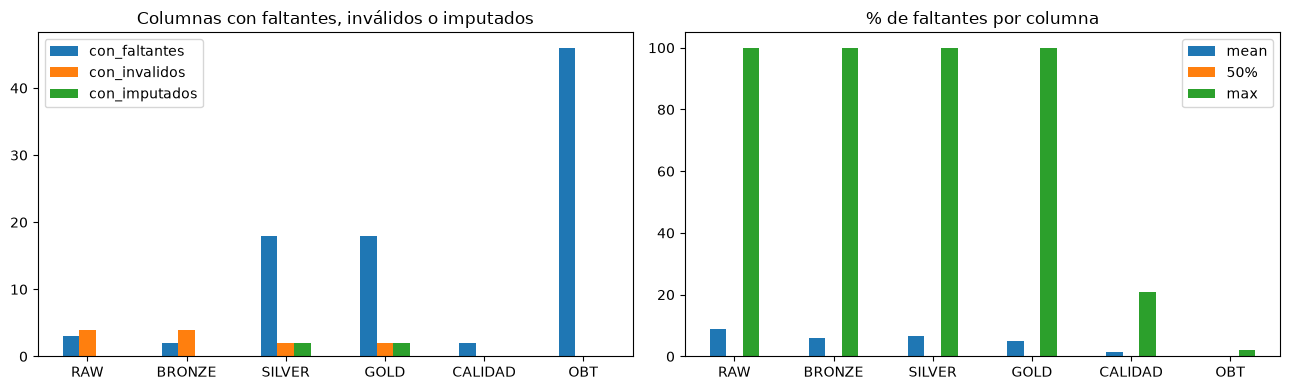

In [6]:
# Resumen por capa: columnas con faltantes, inválidos e imputados.
res = perfil.groupby('capa', observed=True).agg(
    tablas=('tabla', 'nunique'), columnas=('columna', 'size'),
    con_faltantes=('faltantes', lambda s: int((s > 0).sum())),
    pct_faltantes_medio=('pct_faltantes', 'mean'),
    con_regla=('regla_invalido', lambda s: int((s != 'no evaluado').sum())),
    con_invalidos=('invalidos', lambda s: int((s.fillna(0) > 0).sum())),
    invalidos=('invalidos', lambda s: int(s.fillna(0).sum())),
    con_imputados=('imputados', lambda s: int((s.fillna(0) > 0).sum())),
).round(3)
display(res)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
res[['con_faltantes', 'con_invalidos', 'con_imputados']].plot.bar(ax=ax[0], rot=0)
ax[0].set_title('Columnas con faltantes, inválidos o imputados'); ax[0].set_xlabel('')
(perfil.groupby('capa', observed=True).pct_faltantes.describe()[['mean', '50%', 'max']]
       .plot.bar(ax=ax[1], rot=0)); ax[1].set_title('% de faltantes por columna'); ax[1].set_xlabel('')
plt.tight_layout(); plt.show()

### 4.2 Detalle por tabla y columna

Solo las columnas con algo que reportar (faltantes, inválidos, atípicos o imputados). La tabla completa
queda en el CSV de la sección 10.

In [7]:
# Detalle de columnas con faltantes, inválidos, atípicos o imputados.
vista = ['capa', 'tabla', 'columna', 'tipo', 'filas', 'pct_faltantes', 'pct_faltantes_por_imputacion',
         'pct_invalidos', 'regla_invalido', 'pct_atipicos', 'pct_imputados', 'tipo_imputacion']
algo = perfil[(perfil.faltantes > 0) | (perfil.invalidos.fillna(0) > 0) | (perfil.atipicos.fillna(0) > 0)
              | (perfil.imputados.fillna(0) > 0)]
for capa in CAPAS:
    sub = algo[algo.capa == capa]
    print(f'\n=== {capa}: {len(sub)} de {(perfil.capa == capa).sum()} columnas con algo que reportar')
    if len(sub): display(sub[vista].sort_values(['tabla', 'pct_faltantes'], ascending=[True, False]).reset_index(drop=True))


=== RAW: 8 de 33 columnas con algo que reportar


,capa,tabla,columna,tipo,filas,pct_faltantes,pct_faltantes_por_imputacion,pct_invalidos,regla_invalido,pct_atipicos,pct_imputados,tipo_imputacion
0,RAW,INGESTA_LOG,DETALLE,texto,11093,89.7052,NaN,NaN,no evaluado,NaN,NaN,
1,RAW,INGESTA_LOG,TICKER,texto,11093,0.0000,NaN,0.0090,simbolo con minusculas o espacios,NaN,NaN,
2,RAW,INGESTA_LOG,FECHA_HASTA,fecha,11093,0.0000,NaN,4.7507,fin del rango mas alla de manana,NaN,NaN,
3,RAW,LISTADOS_BOLSA,ES_ETF,texto,123267,100.0000,NaN,0.0000,bandera distinta de Y/N,NaN,NaN,
4,RAW,LISTADOS_BOLSA,ES_PRUEBA,texto,123267,100.0000,NaN,0.0000,bandera distinta de Y/N,NaN,NaN,
5,RAW,LISTADOS_BOLSA,SIMBOLO,texto,123267,0.0000,NaN,0.0276,simbolo con minusculas o espacios,NaN,NaN,
6,RAW,PRECIOS_DIARIOS,OPEN,numero,1864395,0.0000,NaN,0.0001,precio <= 0 (^IRX: tasa fuera de -1..20 %),NaN,NaN,
7,RAW,PRECIOS_DIARIOS,VOLUME,numero,1864395,0.0000,NaN,0.0000,conteo o volumen < 0,0.2791,NaN,



=== BRONZE: 7 de 34 columnas con algo que reportar


,capa,tabla,columna,tipo,filas,pct_faltantes,pct_faltantes_por_imputacion,pct_invalidos,regla_invalido,pct_atipicos,pct_imputados,tipo_imputacion
0,BRONZE,BRZ_COMPOSICION_SP500,TICKER,texto,1869975,0.0,NaN,0.0001,simbolo con minusculas o espacios,NaN,NaN,
1,BRONZE,BRZ_COMPOSICION_SP500,TICKER_COMPOSICION,texto,1869975,0.0,NaN,0.0001,simbolo con minusculas o espacios,NaN,NaN,
2,BRONZE,BRZ_COMPOSICION_SP500,TICKER_ORIGINAL,texto,1869975,0.0,NaN,0.0001,simbolo con minusculas o espacios,NaN,NaN,
3,BRONZE,BRZ_LISTADOS_BOLSA,ES_ETF,booleano,6828,100.0,NaN,NaN,no evaluado,NaN,NaN,
4,BRONZE,BRZ_LISTADOS_BOLSA,ES_PRUEBA,booleano,6828,100.0,NaN,NaN,no evaluado,NaN,NaN,
5,BRONZE,BRZ_PRECIOS_DIARIOS,PRECIO_APERTURA,numero,1845167,0.0,NaN,0.0001,precio <= 0 (^IRX: tasa fuera de -1..20 %),NaN,NaN,
6,BRONZE,BRZ_PRECIOS_DIARIOS,VOLUMEN,numero,1845167,0.0,NaN,0.0000,conteo o volumen < 0,0.2797,NaN,



=== SILVER: 24 de 61 columnas con algo que reportar


,capa,tabla,columna,tipo,filas,pct_faltantes,pct_faltantes_por_imputacion,pct_invalidos,regla_invalido,pct_atipicos,pct_imputados,tipo_imputacion
0,SILVER,SLV_ACCIONES,PRIMERA_FECHA_PRECIO,fecha,1130,46.1947,NaN,0.0000,fecha futura,NaN,NaN,
1,SILVER,SLV_ACCIONES,ULTIMA_FECHA_PRECIO,fecha,1130,46.1947,NaN,0.0000,fecha futura,NaN,NaN,
2,SILVER,SLV_ACCIONES,ULTIMA_FECHA_SP500,fecha,1130,44.5133,NaN,NaN,no evaluado,NaN,NaN,
3,SILVER,SLV_ACCIONES,NOMBRE,texto,1130,38.8496,NaN,NaN,no evaluado,NaN,NaN,
4,SILVER,SLV_ACCIONES,CODIGO_BOLSA,texto,1130,38.8496,NaN,0.0000,codigo de bolsa desconocido,NaN,NaN,
5,SILVER,SLV_ACCIONES,BOLSA,texto,1130,38.8496,NaN,NaN,no evaluado,NaN,NaN,
6,SILVER,SLV_ACCIONES,TICKER,texto,1130,0.0000,NaN,0.0885,simbolo con minusculas o espacios,NaN,NaN,
7,SILVER,SLV_MEMBRESIA_SP500,FECHA_FIN,fecha,1179,42.6633,NaN,NaN,no evaluado,NaN,NaN,
8,SILVER,SLV_MEMBRESIA_SP500,TICKER,texto,1179,0.0000,NaN,0.0848,simbolo con minusculas o espacios,NaN,NaN,
9,SILVER,SLV_MERCADO_DIARIO,RET_LOG_SP500,numero,4245,0.0236,NaN,NaN,no evaluado,NaN,NaN,


... (2 outputs left out)


=== CALIDAD: 2 de 27 columnas con algo que reportar


,capa,tabla,columna,tipo,filas,pct_faltantes,pct_faltantes_por_imputacion,pct_invalidos,regla_invalido,pct_atipicos,pct_imputados,tipo_imputacion
0,CALIDAD,DQ_HUECOS_POR_TICKER,PRIMERA_COTIZACION,fecha,768,20.8333,NaN,0.0,fecha futura,NaN,NaN,
1,CALIDAD,DQ_HUECOS_POR_TICKER,ULTIMA_COTIZACION,fecha,768,20.8333,NaN,0.0,fecha futura,NaN,NaN,



=== OBT: 48 de 113 columnas con algo que reportar


,capa,tabla,columna,tipo,filas,pct_faltantes,pct_faltantes_por_imputacion,pct_invalidos,regla_invalido,pct_atipicos,pct_imputados,tipo_imputacion
0,OBT,OBT_ACCION_DIA,DIF_CIERRE_AJUSTADO,numero,1832433,0.0338,NaN,NaN,no evaluado,NaN,0.0,derivada del valor imputado
1,OBT,OBT_ACCION_DIA,RET_PCT_DIARIO,numero,1832433,0.0338,NaN,0.0,variacion simple < -100 %,NaN,0.0,derivada del valor imputado
2,OBT,OBT_ACCION_DIA,RET_LOG_DIARIO,numero,1832433,0.0338,NaN,NaN,no evaluado,0.0031,0.0,derivada del valor imputado
3,OBT,OBT_ACCION_DIA,DIF_APERTURA_AJUSTADA,numero,1832433,0.0338,NaN,NaN,no evaluado,NaN,0.0,derivada del valor imputado
4,OBT,OBT_ACCION_DIA,RET_PCT_APERTURA,numero,1832433,0.0338,NaN,0.0,variacion simple < -100 %,NaN,0.0,derivada del valor imputado
5,OBT,OBT_ACCION_DIA,RET_LOG_APERTURA,numero,1832433,0.0338,NaN,NaN,no evaluado,0.0025,0.0,derivada del valor imputado
6,OBT,OBT_ACCION_DIA,RET_PCT_NOCTURNO,numero,1832433,0.0338,NaN,0.0,variacion simple < -100 %,NaN,0.0,derivada del valor imputado
7,OBT,OBT_ACCION_DIA,RET_LOG_NOCTURNO,numero,1832433,0.0338,NaN,NaN,no evaluado,0.0016,0.0,derivada del valor imputado
8,OBT,OBT_ACCION_DIA,RET_LOG_SP500,numero,1832433,0.0186,NaN,NaN,no evaluado,NaN,NaN,
9,OBT,OBT_ACCION_DIA,VOLUMEN,numero,1832433,0.0000,0.0,0.0,conteo o volumen < 0,0.0497,NaN,no observada en el dia imputado


## 5. La misma variable a lo largo de las capas

Cómo cambian los faltantes, inválidos e imputados de una variable al pasar por la limpieza. Cada fila es
un concepto y cada columna la tabla donde vive en esa capa.


pct_faltantes


tabla,RAW.PRECIOS_DIARIOS,BRONZE.BRZ_PRECIOS_DIARIOS,SILVER.SLV_PRECIOS_ACCIONES,GOLD.FCT_PRECIOS_DIARIOS,OBT.OBT_ACCION_DIA,OBT.OBT_ACCION_MES,SILVER.SLV_MERCADO_DIARIO,GOLD.FCT_MERCADO_DIARIO
concepto,,,,,,,,
apertura,0.0,0.0,0.0000,0.0000,0.0000,NaN,NaN,NaN
cierre,0.0,0.0,0.0000,0.0000,0.0000,NaN,NaN,NaN
cierre ajustado,0.0,0.0,0.0000,0.0000,0.0000,0.0000,NaN,NaN
maximo,0.0,0.0,0.0000,0.0000,0.0000,NaN,NaN,NaN
minimo,0.0,0.0,0.0000,0.0000,0.0000,NaN,NaN,NaN
retorno log,NaN,NaN,0.0338,0.0338,0.0338,0.0046,NaN,NaN
tasa ^IRX,NaN,NaN,NaN,NaN,NaN,0.0000,0.0,0.0
volumen,0.0,0.0,0.0000,0.0000,0.0000,NaN,NaN,NaN



pct_invalidos


tabla,RAW.PRECIOS_DIARIOS,BRONZE.BRZ_PRECIOS_DIARIOS,SILVER.SLV_PRECIOS_ACCIONES,GOLD.FCT_PRECIOS_DIARIOS,OBT.OBT_ACCION_DIA,OBT.OBT_ACCION_MES,SILVER.SLV_MERCADO_DIARIO,GOLD.FCT_MERCADO_DIARIO
concepto,,,,,,,,
apertura,0.0001,0.0001,0.0,0.0,0.0,NaN,NaN,NaN
cierre,0.0000,0.0000,0.0,0.0,0.0,NaN,NaN,NaN
cierre ajustado,0.0000,0.0000,0.0,0.0,0.0,0.0,NaN,NaN
maximo,0.0000,0.0000,0.0,0.0,0.0,NaN,NaN,NaN
minimo,0.0000,0.0000,0.0,0.0,0.0,NaN,NaN,NaN
retorno log,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tasa ^IRX,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0
volumen,0.0000,0.0000,0.0,0.0,0.0,NaN,NaN,NaN



pct_imputados


tabla,RAW.PRECIOS_DIARIOS,BRONZE.BRZ_PRECIOS_DIARIOS,SILVER.SLV_PRECIOS_ACCIONES,GOLD.FCT_PRECIOS_DIARIOS,OBT.OBT_ACCION_DIA,OBT.OBT_ACCION_MES,SILVER.SLV_MERCADO_DIARIO,GOLD.FCT_MERCADO_DIARIO
concepto,,,,,,,,
apertura,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cierre,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cierre ajustado,NaN,NaN,0.0,0.0,0.0,NaN,NaN,NaN
maximo,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
minimo,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
retorno log,NaN,NaN,0.0,0.0,0.0,NaN,NaN,NaN
tasa ^IRX,NaN,NaN,NaN,NaN,NaN,NaN,0.0471,0.0471
volumen,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


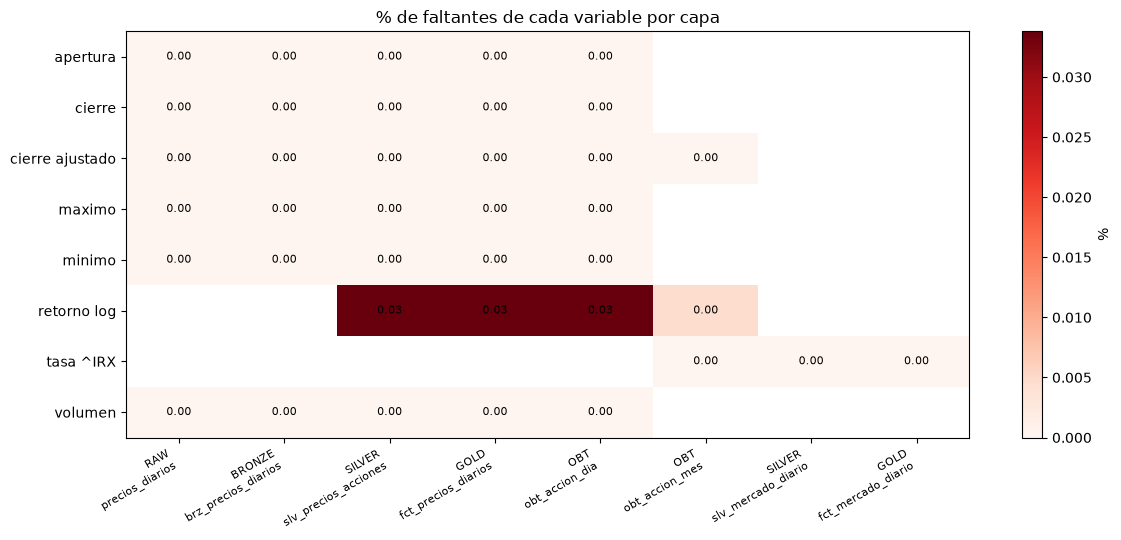

In [8]:
# Linaje de variables de precio y mercado entre capas.
LINAJE = {
    'apertura':        {'RAW.PRECIOS_DIARIOS': 'OPEN', 'BRONZE.BRZ_PRECIOS_DIARIOS': 'PRECIO_APERTURA',
                        'SILVER.SLV_PRECIOS_ACCIONES': 'PRECIO_APERTURA', 'GOLD.FCT_PRECIOS_DIARIOS': 'PRECIO_APERTURA',
                        'OBT.OBT_ACCION_DIA': 'PRECIO_APERTURA'},
    'maximo':          {'RAW.PRECIOS_DIARIOS': 'HIGH', 'BRONZE.BRZ_PRECIOS_DIARIOS': 'PRECIO_MAXIMO',
                        'SILVER.SLV_PRECIOS_ACCIONES': 'PRECIO_MAXIMO', 'GOLD.FCT_PRECIOS_DIARIOS': 'PRECIO_MAXIMO',
                        'OBT.OBT_ACCION_DIA': 'PRECIO_MAXIMO'},
    'minimo':          {'RAW.PRECIOS_DIARIOS': 'LOW', 'BRONZE.BRZ_PRECIOS_DIARIOS': 'PRECIO_MINIMO',
                        'SILVER.SLV_PRECIOS_ACCIONES': 'PRECIO_MINIMO', 'GOLD.FCT_PRECIOS_DIARIOS': 'PRECIO_MINIMO',
                        'OBT.OBT_ACCION_DIA': 'PRECIO_MINIMO'},
    'cierre':          {'RAW.PRECIOS_DIARIOS': 'CLOSE', 'BRONZE.BRZ_PRECIOS_DIARIOS': 'PRECIO_CIERRE',
                        'SILVER.SLV_PRECIOS_ACCIONES': 'PRECIO_CIERRE', 'GOLD.FCT_PRECIOS_DIARIOS': 'PRECIO_CIERRE',
                        'OBT.OBT_ACCION_DIA': 'PRECIO_CIERRE'},
    'cierre ajustado': {'RAW.PRECIOS_DIARIOS': 'ADJ_CLOSE', 'BRONZE.BRZ_PRECIOS_DIARIOS': 'PRECIO_CIERRE_AJUSTADO',
                        'SILVER.SLV_PRECIOS_ACCIONES': 'PRECIO_CIERRE_AJUSTADO', 'GOLD.FCT_PRECIOS_DIARIOS': 'PRECIO_CIERRE_AJUSTADO',
                        'OBT.OBT_ACCION_DIA': 'PRECIO_CIERRE_AJUSTADO', 'OBT.OBT_ACCION_MES': 'PRECIO_CIERRE_AJUSTADO'},
    'volumen':         {'RAW.PRECIOS_DIARIOS': 'VOLUME', 'BRONZE.BRZ_PRECIOS_DIARIOS': 'VOLUMEN',
                        'SILVER.SLV_PRECIOS_ACCIONES': 'VOLUMEN', 'GOLD.FCT_PRECIOS_DIARIOS': 'VOLUMEN',
                        'OBT.OBT_ACCION_DIA': 'VOLUMEN'},
    'retorno log':     {'SILVER.SLV_PRECIOS_ACCIONES': 'RET_LOG_DIARIO', 'GOLD.FCT_PRECIOS_DIARIOS': 'RET_LOG_DIARIO',
                        'OBT.OBT_ACCION_DIA': 'RET_LOG_DIARIO', 'OBT.OBT_ACCION_MES': 'RET_LOG_MES'},
    'tasa ^IRX':       {'SILVER.SLV_MERCADO_DIARIO': 'TASA_IRX_ANUAL_PCT', 'GOLD.FCT_MERCADO_DIARIO': 'TASA_IRX_ANUAL_PCT',
                        'OBT.OBT_ACCION_MES': 'TASA_IRX_PROM_MES_PCT'},
}
p = perfil.assign(tabla_completa=perfil.capa.astype(str) + '.' + perfil.tabla).set_index(['tabla_completa', 'columna'])
filas = []
for concepto, donde in LINAJE.items():
    for t, c in donde.items():
        if (t, c) in p.index:
            r = p.loc[(t, c)]
            filas.append({'concepto': concepto, 'tabla': t, 'filas': r.filas, 'pct_faltantes': r.pct_faltantes,
                          'pct_invalidos': r.pct_invalidos, 'pct_imputados': r.pct_imputados})
linaje = pd.DataFrame(filas)
orden_t = [t for t in dict.fromkeys(t for d in LINAJE.values() for t in d) if t in set(linaje.tabla)]
for m in ['pct_faltantes', 'pct_invalidos', 'pct_imputados']:
    print(f'\n{m}'); display(linaje.pivot(index='concepto', columns='tabla', values=m)[orden_t].round(4))

fig, ax = plt.subplots(figsize=(12, 5.5))
mat = linaje.pivot(index='concepto', columns='tabla', values='pct_faltantes')[orden_t]
im = ax.imshow(mat.values.astype(float), cmap='Reds', aspect='auto')
ax.set_xticks(range(len(orden_t)), [t.split('.')[0] + '\n' + t.split('.')[1].lower() for t in orden_t], fontsize=8, rotation=30, ha='right')
ax.set_yticks(range(len(mat)), mat.index)
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        v = mat.values[i, j]
        if pd.notna(v): ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=8)
ax.set_title('% de faltantes de cada variable por capa'); fig.colorbar(im, ax=ax, label='%'); plt.tight_layout(); plt.show()

## 6. Flujo de filas de precios entre capas

Cuántas filas entran y salen de cada nivel, y por qué cambian.

,tabla,filas,que pasa
0,RAW.PRECIOS_DIARIOS,1864395,"incluye 23276 filas en 4048 (ticker, fecha) ca..."
1,BRONZE.BRZ_PRECIOS_DIARIOS,1845167,"una fila por (ticker, fecha): quita 19228 carg..."
2,BRONZE (solo acciones),1832434,"sin ^GSPC, ^NYA, ^IRX"
3,SILVER.SLV_PRECIOS_ACCIONES,1832433,1832433 observadas + 0 imputadas; 1 filas de B...
4,GOLD.FCT_PRECIOS_DIARIOS,1832433,mismas filas que Silver; 1787760 con la accion...
5,OBT.OBT_ACCION_DIA,1832433,una fila por fila de Gold (control de Spark)
6,OBT.OBT_ACCION_MES,87178,"accion x mes cerrado; 58628 elegibles, 86558 c..."


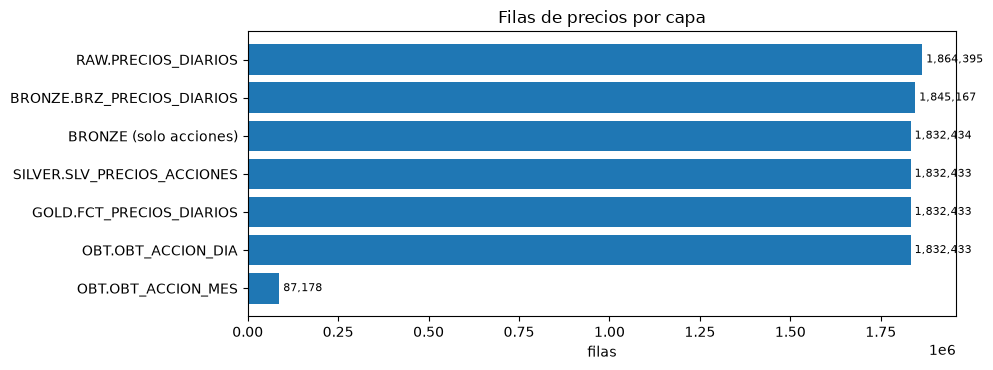

In [9]:
# Flujo de filas: RAW -> Bronze -> Silver -> Gold -> OBT.
q1 = lambda sql: consulta(sql).iloc[0].to_dict()
raw = q1("""select count(*) filas,
                   sum(case when TICKER like '^%' then 1 else 0 end) indices
            from RAW.PRECIOS_DIARIOS""")
raw_dup = q1("""select count(*) grupos, coalesce(sum(n), 0) filas from
                (select TICKER, FECHA, count(*) n from RAW.PRECIOS_DIARIOS group by TICKER, FECHA having count(*) > 1) d""")
brz = q1("""select count(*) filas, sum(case when ES_INDICE then 1 else 0 end) indices from BRONZE.BRZ_PRECIOS_DIARIOS""")
slv = q1("""select count(*) filas, sum(case when IMPUTADO then 1 else 0 end) imputadas,
                   sum(case when DESPUES_DE_TRAMO_EXCLUIDO then 1 else 0 end) tras_tramo_excluido
            from SILVER.SLV_PRECIOS_ACCIONES""")
gld = q1("""select count(*) filas, sum(case when IMPUTADO then 1 else 0 end) imputadas,
                   sum(case when EN_SP500 then 1 else 0 end) en_sp500 from GOLD.FCT_PRECIOS_DIARIOS""")
dia = q1('select count(*) filas from OBT.OBT_ACCION_DIA')
mes = q1("""select count(*) filas, sum(case when ELEGIBLE then 1 else 0 end) elegibles,
                   sum(case when RET_LOG_MES_SIGUIENTE is not null then 1 else 0 end) con_objetivo
            from OBT.OBT_ACCION_MES""")
acciones_brz = int(brz['filas']) - int(brz['indices'] or 0)
observadas_slv = int(slv['filas']) - int(slv['imputadas'] or 0)
flujo = pd.DataFrame([
    ('RAW.PRECIOS_DIARIOS', raw['filas'], f"incluye {int(raw_dup['filas'])} filas en {int(raw_dup['grupos'])} (ticker, fecha) cargadas mas de una vez y {int(raw['indices'] or 0)} de indices"),
    ('BRONZE.BRZ_PRECIOS_DIARIOS', brz['filas'], f"una fila por (ticker, fecha): quita {int(raw['filas']) - int(brz['filas'])} cargas repetidas; {int(brz['indices'] or 0)} de indices pasan a Silver.mercado"),
    ('BRONZE (solo acciones)', acciones_brz, 'sin ^GSPC, ^NYA, ^IRX'),
    ('SILVER.SLV_PRECIOS_ACCIONES', slv['filas'], f"{observadas_slv} observadas + {int(slv['imputadas'] or 0)} imputadas; {acciones_brz - observadas_slv} filas de Bronze no pasan (precio invalido o fuera de la vida de la accion)"),
    ('GOLD.FCT_PRECIOS_DIARIOS', gld['filas'], f"mismas filas que Silver; {int(gld['en_sp500'] or 0)} con la accion en el S&P 500 ese dia"),
    ('OBT.OBT_ACCION_DIA', dia['filas'], 'una fila por fila de Gold (control de Spark)'),
    ('OBT.OBT_ACCION_MES', mes['filas'], f"accion x mes cerrado; {int(mes['elegibles'] or 0)} elegibles, {int(mes['con_objetivo'] or 0)} con objetivo"),
], columns=['tabla', 'filas', 'que pasa'])
flujo['filas'] = flujo.filas.astype(int)
display(flujo)
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.barh(flujo.tabla[::-1], flujo.filas[::-1], color='tab:blue')
for y, v in enumerate(flujo.filas[::-1]): ax.text(v, y, f' {v:,}', va='center', fontsize=8)
ax.set_title('Filas de precios por capa'); ax.set_xlabel('filas'); plt.tight_layout(); plt.show()

## 7. Claves duplicadas e inconsistencias entre columnas

Un hecho limpio tiene una sola fila por clave y un día de precios coherente (mínimo ≤ apertura, cierre ≤
máximo). RAW es *append-only*: ahí se esperan duplicados; desde Bronze no debe quedar ninguno.

In [10]:
# Duplicados por clave natural de cada tabla y coherencia OHLC por capa.
CLAVES = {'RAW.PRECIOS_DIARIOS': ['TICKER', 'FECHA'], 'RAW.COMPOSICION_SP500': ['LOTE_ID', 'FECHA'],
          'BRONZE.BRZ_PRECIOS_DIARIOS': ['TICKER', 'FECHA'], 'BRONZE.BRZ_COMPOSICION_SP500': ['FECHA_FOTO', 'TICKER'],
          'BRONZE.BRZ_LISTADOS_BOLSA': ['TICKER'], 'SILVER.SLV_PRECIOS_ACCIONES': ['TICKER', 'FECHA'],
          'SILVER.SLV_MERCADO_DIARIO': ['FECHA'], 'SILVER.SLV_MEMBRESIA_SP500': ['PERIODO_KEY'],
          'SILVER.SLV_ACCIONES': ['TICKER'], 'GOLD.DIM_ACCION': ['ACCION_KEY'], 'GOLD.DIM_FECHA': ['FECHA_KEY'],
          'GOLD.DIM_MEMBRESIA_SP500': ['PERIODO_KEY'], 'GOLD.FCT_PRECIOS_DIARIOS': ['ACCION_KEY', 'FECHA_KEY'],
          'GOLD.FCT_MERCADO_DIARIO': ['FECHA_KEY'], 'CALIDAD.DQ_METRICAS': ['METRICA'],
          'OBT.OBT_ACCION_MES': ['ACCION_KEY', 'ANIO_MES'], 'OBT.OBT_ACCION_DIA': ['ACCION_KEY', 'FECHA']}
existentes = set(tablas.capa.astype(str) + '.' + tablas.tabla)
dup = []
for t, k in CLAVES.items():
    if t not in existentes: continue
    r = q1(f"select count(*) grupos, coalesce(sum(n), 0) filas from (select {', '.join(k)}, count(*) n from {t} group by {', '.join(k)} having count(*) > 1) d")
    dup.append({'tabla': t, 'clave': ' + '.join(k), 'claves_repetidas': int(r['grupos']), 'filas_en_claves_repetidas': int(r['filas'])})
display(pd.DataFrame(dup))

OHLC = {'RAW.PRECIOS_DIARIOS': ('OPEN', 'HIGH', 'LOW', 'CLOSE', "TICKER NOT LIKE '^%'"),
        'BRONZE.BRZ_PRECIOS_DIARIOS': ('PRECIO_APERTURA', 'PRECIO_MAXIMO', 'PRECIO_MINIMO', 'PRECIO_CIERRE', 'NOT ES_INDICE'),
        'SILVER.SLV_PRECIOS_ACCIONES': ('PRECIO_APERTURA', 'PRECIO_MAXIMO', 'PRECIO_MINIMO', 'PRECIO_CIERRE', '1=1'),
        'GOLD.FCT_PRECIOS_DIARIOS': ('PRECIO_APERTURA', 'PRECIO_MAXIMO', 'PRECIO_MINIMO', 'PRECIO_CIERRE', '1=1'),
        'OBT.OBT_ACCION_DIA': ('PRECIO_APERTURA', 'PRECIO_MAXIMO', 'PRECIO_MINIMO', 'PRECIO_CIERRE', '1=1')}
inc = []
for t, (o, h, l, c, filtro) in OHLC.items():
    r = q1(f"""select count(*) filas,
                      sum(case when {h} < {l} then 1 else 0 end) maximo_menor_que_minimo,
                      sum(case when {c} > {h} * 1.001 or {c} < {l} * 0.999 then 1 else 0 end) cierre_fuera_de_rango,
                      sum(case when {o} > {h} * 1.001 or {o} < {l} * 0.999 then 1 else 0 end) apertura_fuera_de_rango
               from {t} where {filtro}""")
    inc.append({'tabla': t, **{k: int(v or 0) for k, v in r.items()}})
if 'OBT.OBT_ACCION_DIA' in existentes:
    r = q1("select sum(case when PRECIO_MAXIMO_AJUSTADO < PRECIO_MINIMO_AJUSTADO then 1 else 0 end) n from OBT.OBT_ACCION_DIA")
    print(f"OBT_ACCION_DIA con maximo ajustado < minimo ajustado: {int(r['n'] or 0)}")
inconsistencias = pd.DataFrame(inc)
for m in ['maximo_menor_que_minimo', 'cierre_fuera_de_rango', 'apertura_fuera_de_rango']:
    inconsistencias[f'pct_{m}'] = (100 * inconsistencias[m] / inconsistencias.filas).round(4)
display(inconsistencias)

,tabla,clave,claves_repetidas,filas_en_claves_repetidas
0,RAW.PRECIOS_DIARIOS,TICKER + FECHA,4048,23276
1,RAW.COMPOSICION_SP500,LOTE_ID + FECHA,306,612
2,BRONZE.BRZ_PRECIOS_DIARIOS,TICKER + FECHA,0,0
3,BRONZE.BRZ_COMPOSICION_SP500,FECHA_FOTO + TICKER,0,0
4,BRONZE.BRZ_LISTADOS_BOLSA,TICKER,0,0
5,SILVER.SLV_PRECIOS_ACCIONES,TICKER + FECHA,0,0
6,SILVER.SLV_MERCADO_DIARIO,FECHA,0,0
7,SILVER.SLV_MEMBRESIA_SP500,PERIODO_KEY,0,0
8,SILVER.SLV_ACCIONES,TICKER,0,0
9,GOLD.DIM_ACCION,ACCION_KEY,0,0


OBT_ACCION_DIA con maximo ajustado < minimo ajustado: 0


,tabla,filas,maximo_menor_que_minimo,cierre_fuera_de_rango,apertura_fuera_de_rango,pct_maximo_menor_que_minimo,pct_cierre_fuera_de_rango,pct_apertura_fuera_de_rango
0,RAW.PRECIOS_DIARIOS,1851548,0,0,39,0.0,0.0,0.0021
1,BRONZE.BRZ_PRECIOS_DIARIOS,1832434,0,0,6,0.0,0.0,0.0003
2,SILVER.SLV_PRECIOS_ACCIONES,1832433,0,0,5,0.0,0.0,0.0003
3,GOLD.FCT_PRECIOS_DIARIOS,1832433,0,0,5,0.0,0.0,0.0003
4,OBT.OBT_ACCION_DIA,1832433,0,0,5,0.0,0.0,0.0003


## 8. Imputados

Qué se imputó, cuánto y dónde. En Silver solo se rellenan huecos de hasta 5 días bursátiles; los más
largos se excluyen. La tasa ^IRX se rellena con el último valor cuando no cotiza un día de NYSE.

,anio,dias,imputados,tras_tramo_excluido,retornos_extremos,pct_imputados
0,2010,85680,0,0,7,0.0
1,2011,87900,0,0,7,0.0
2,2012,90089,0,0,7,0.0
3,2013,93637,0,0,1,0.0
4,2014,94931,0,0,1,0.0
5,2015,97864,0,0,0,0.0
6,2016,103643,0,0,2,0.0
7,2017,107796,0,2,0,0.0
8,2018,110942,0,0,2,0.0
9,2019,115317,0,3,2,0.0


,largo,dias


Acciones con mas dias imputados o excluidos:


,ticker,dias_vida,dias_imputados,dias_excluidos,pct_huecos_miembro
0,JBL,4245,0,2014,0.0000
1,TER,4245,0,1510,0.0000
2,LDOS,4245,0,1258,0.0000
3,TMUS,4245,0,1258,0.0000
4,FSLR,4245,0,1008,0.0000
5,AMCR,3649,0,1006,19.1455
6,EQT,4245,0,757,0.0000
7,KDP,4245,0,757,0.0000
8,AMD,4245,0,756,0.0000
9,PCG,4245,0,505,0.0000


^IRX: 2 de 4245 dias rellenados con el ultimo valor; 0 dias sin tasa (antes del primer dato).
OBT_ACCION_MES: 0 de 87178 filas (accion x mes) tienen al menos un dia imputado (0 elegibles).


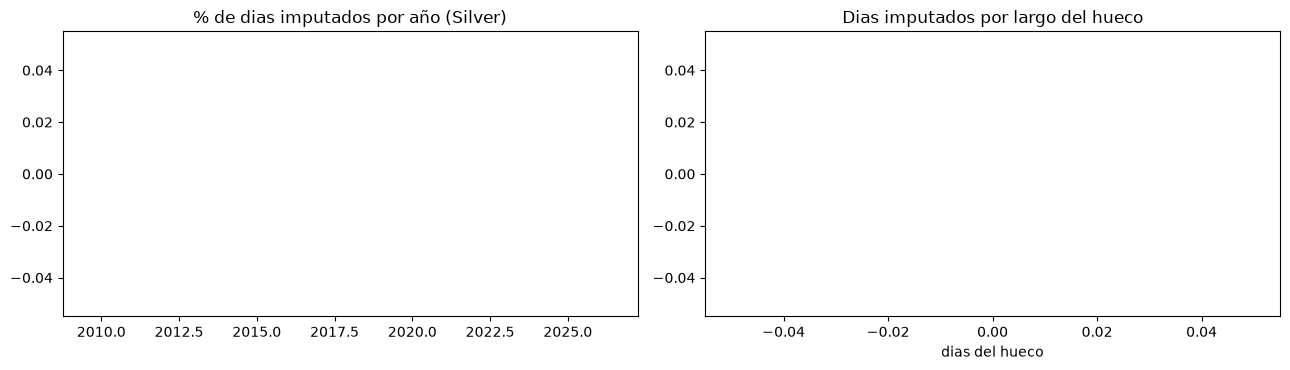

In [11]:
# Imputados: por año, por largo del hueco, acciones con más días imputados, ^IRX y efecto en la OBT mensual.
por_anio = consulta("""select extract(year from FECHA) anio, count(*) dias,
                              sum(case when IMPUTADO then 1 else 0 end) imputados,
                              sum(case when DESPUES_DE_TRAMO_EXCLUIDO then 1 else 0 end) tras_tramo_excluido,
                              sum(case when ES_RETORNO_EXTREMO then 1 else 0 end) retornos_extremos
                       from SILVER.SLV_PRECIOS_ACCIONES group by 1 order by 1""")
por_anio['pct_imputados'] = (100 * por_anio.imputados / por_anio.dias).round(4)
display(por_anio)
largo = consulta("""select LARGO_HUECO_IMPUTADO largo, count(*) dias from SILVER.SLV_PRECIOS_ACCIONES
                    where IMPUTADO group by 1 order by 1""")
display(largo)
top = consulta("""select TICKER, DIAS_VIDA, DIAS_IMPUTADOS, DIAS_EXCLUIDOS, PCT_HUECOS_MIEMBRO
                  from CALIDAD.DQ_HUECOS_POR_TICKER where DIAS_IMPUTADOS > 0 or DIAS_EXCLUIDOS > 0
                  order by DIAS_IMPUTADOS + DIAS_EXCLUIDOS desc limit 15""")
print('Acciones con mas dias imputados o excluidos:'); display(top)
irx = q1("""select count(*) dias, sum(case when TASA_IRX_RELLENADA then 1 else 0 end) rellenados,
                   sum(case when TASA_IRX_ANUAL_PCT is null then 1 else 0 end) sin_tasa
            from SILVER.SLV_MERCADO_DIARIO""")
print(f"^IRX: {int(irx['rellenados'] or 0)} de {int(irx['dias'])} dias rellenados con el ultimo valor; "
      f"{int(irx['sin_tasa'] or 0)} dias sin tasa (antes del primer dato).")
obt_imp = q1("""select count(*) filas, sum(case when DIAS_IMPUTADOS_MES > 0 then 1 else 0 end) con_imputados,
                       sum(case when DIAS_IMPUTADOS_MES > 0 and ELEGIBLE then 1 else 0 end) elegibles_con_imputados,
                       sum(DIAS_IMPUTADOS_MES) dias_imputados, sum(DIAS_NEGOCIADOS_MES) dias_negociados
                from OBT.OBT_ACCION_MES""")
print(f"OBT_ACCION_MES: {int(obt_imp['con_imputados'] or 0)} de {int(obt_imp['filas'])} filas (accion x mes) "
      f"tienen al menos un dia imputado ({int(obt_imp['elegibles_con_imputados'] or 0)} elegibles).")

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].bar(por_anio.anio.astype(int), por_anio.pct_imputados, color='tab:orange'); ax[0].set_title('% de dias imputados por año (Silver)')
ax[1].bar(largo.largo.astype(int), largo.dias, color='tab:orange'); ax[1].set_title('Dias imputados por largo del hueco'); ax[1].set_xlabel('dias del hueco')
plt.tight_layout(); plt.show()

## 9. Tablas finales de la OBT

Faltantes de cada columna de `OBT_ACCION_MES` en todas las filas y **solo en las elegibles**, que son las
que usa el modelo, con la razón esperada del nulo. Luego los atípicos de los predictores (Tukey IQR y
z ≥ 3), los controles de Spark (`VALIDACION_OBT`) y las métricas de `CALIDAD.DQ_METRICAS`.

OBT_ACCION_MES: 75 columnas en la base; esperadas por src/pipeline.py: 75; faltan: ninguna


Filas: 87178; elegibles: 58628


,columna,pct_faltantes,pct_faltantes_elegibles,origen,uso,razon_del_nulo
0,ret_pct_mes_siguiente,0.711,0.583,F1 (PSet 3),nunca predictor (fuga),futuro: nulo en el ultimo mes cerrado y sin me...
1,ret_log_mes_siguiente,0.711,0.583,PSet 2,objetivo,futuro: nulo en el ultimo mes cerrado y sin me...
2,rf_mes_siguiente,0.593,0.583,PSet 2,nunca predictor (fuga),futuro: nulo en el ultimo mes cerrado y sin me...
3,ret_log_nyse_composite_mes_siguiente,0.593,0.583,PSet 2,nunca predictor (fuga),futuro: nulo en el ultimo mes cerrado y sin me...
4,ret_log_sp500_mes_siguiente,0.593,0.583,PSet 2,nunca predictor (fuga),futuro: nulo en el ultimo mes cerrado y sin me...
5,exceso_ret_mes_siguiente,0.711,0.583,PSet 2,nunca predictor (fuga),futuro: nulo en el ultimo mes cerrado y sin me...
6,nombre,0.167,0.196,PSet 2,informativa,atributo actual: accion que ya no cotiza
7,cambio_rango_log_hl_21_63,0.031,0.017,F1 (PSet 3),predictor,ventana de 63 dias: historia corta
8,cambio_rango_pct_hl_mes,0.740,0.015,F1 (PSet 3),informativa,requiere el mes anterior
9,cambio_rango_pct_hl_21_63,0.020,0.012,F1 (PSet 3),informativa,ventana de 63 dias: historia corta


Columnas sin ningun nulo: 38 de 75


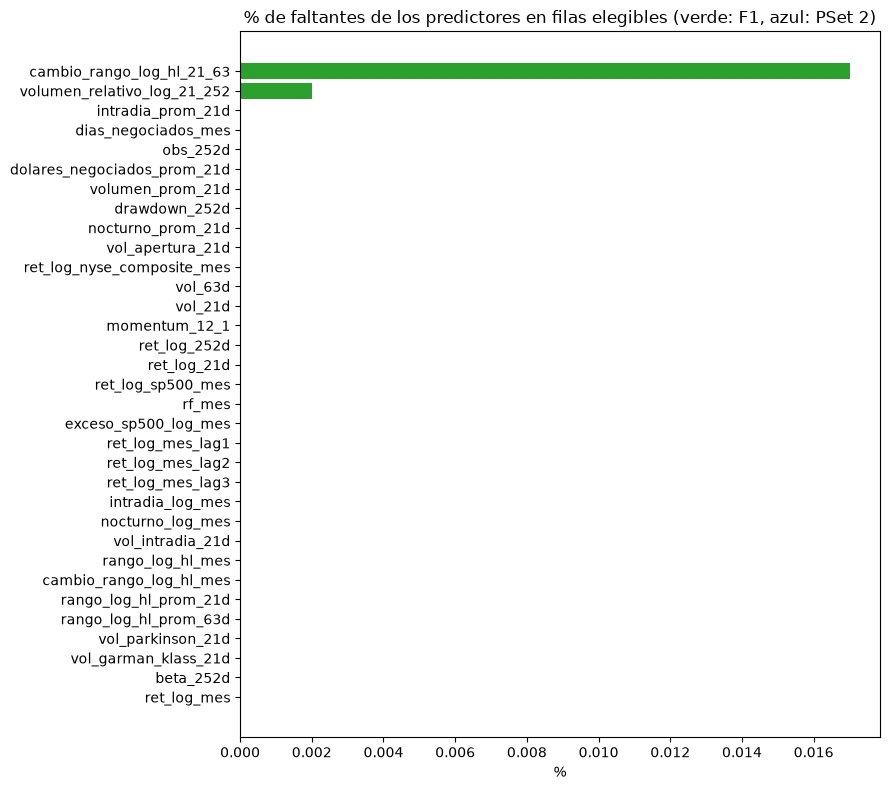

In [12]:
# OBT_ACCION_MES: faltantes en todas las filas y en las elegibles, con la razón esperada.
import sys
sys.path.insert(0, str(R.parent))
from src.pipeline import OBT_MES_PSET2, OBT_MES_F1, FEATURES_OBT, FUGA, TARGET

cols_mes = [c for c in col[(col.table_schema == 'OBT') & (col.table_name == 'OBT_ACCION_MES')].columna]
faltan = sorted(set(c.upper() for c in OBT_MES_PSET2 + OBT_MES_F1) - set(cols_mes))
print(f'OBT_ACCION_MES: {len(cols_mes)} columnas en la base; esperadas por src/pipeline.py: {len(OBT_MES_PSET2) + len(OBT_MES_F1)}; faltan: {faltan or "ninguna"}')
exprs = ', '.join(f'SUM(CASE WHEN {c} IS NULL THEN 1 ELSE 0 END) AS {c}' for c in cols_mes)
f_todas = consulta(f'select count(*) n__, {exprs} from OBT.OBT_ACCION_MES').iloc[0]
f_eleg = consulta(f'select count(*) n__, {exprs} from OBT.OBT_ACCION_MES where ELEGIBLE').iloc[0]

def razon(c):
    c = c.lower()
    if c in FUGA or 'siguiente' in c: return 'futuro: nulo en el ultimo mes cerrado y sin mes siguiente consecutivo'
    if 'lag' in c: return 'rezago: requiere meses previos consecutivos'
    if '252' in c or c in ('momentum_12_1', 'beta_252d', 'drawdown_252d'): return 'ventana de 252 dias: historia corta'
    if '63' in c: return 'ventana de 63 dias: historia corta'
    if c.startswith('cambio_rango') and c.endswith('_mes'): return 'requiere el mes anterior'
    if c in ('rf_mes', 'tasa_irx_prom_mes_pct'): return 'mercado: depende de ^IRX'
    if c in ('nombre', 'bolsa'): return 'atributo actual: accion que ya no cotiza'
    return ''
obt_f = pd.DataFrame({'columna': [c.lower() for c in cols_mes],
                      'pct_faltantes': [100 * f_todas[c.lower()] / max(f_todas['n__'], 1) for c in cols_mes],
                      'pct_faltantes_elegibles': [100 * f_eleg[c.lower()] / max(f_eleg['n__'], 1) for c in cols_mes]})
obt_f['origen'] = np.where(obt_f.columna.isin(OBT_MES_F1), 'F1 (PSet 3)', 'PSet 2')
obt_f['uso'] = np.select([obt_f.columna == TARGET, obt_f.columna.isin(FUGA), obt_f.columna.isin(FEATURES_OBT)],
                         ['objetivo', 'nunca predictor (fuga)', 'predictor'], 'informativa')
obt_f['razon_del_nulo'] = obt_f.columna.map(razon)
obt_f = obt_f.round(3)
print(f"Filas: {int(f_todas['n__'])}; elegibles: {int(f_eleg['n__'])}")
display(obt_f[obt_f.pct_faltantes > 0].sort_values('pct_faltantes_elegibles', ascending=False).reset_index(drop=True))
print(f'Columnas sin ningun nulo: {(obt_f.pct_faltantes == 0).sum()} de {len(obt_f)}')

pred = obt_f[obt_f.uso == 'predictor'].sort_values('pct_faltantes_elegibles')
fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(pred.columna, pred.pct_faltantes_elegibles, color=np.where(pred.origen == 'F1 (PSet 3)', 'tab:green', 'tab:blue'))
ax.set_title('% de faltantes de los predictores en filas elegibles (verde: F1, azul: PSet 2)'); ax.set_xlabel('%')
plt.tight_layout(); plt.show()

,n,pct_iqr_leve,pct_iqr_extremo,pct_z_ge_3,asimetria,curtosis
volumen_prom_21d,58628,8.885,4.239,1.537,11.308,257.559
dolares_negociados_prom_21d,58628,9.187,4.046,1.992,5.347,72.334
cambio_rango_log_hl_mes,58628,6.035,2.062,1.556,2.947,46.086
obs_252d,58628,2.001,2.001,1.300,-9.707,97.076
vol_63d,58628,5.468,1.979,1.997,2.996,16.191
vol_21d,58628,5.105,1.788,1.714,3.815,28.406
nocturno_prom_21d,58628,6.504,1.701,1.660,-1.291,14.617
nocturno_log_mes,58628,6.371,1.678,1.675,-1.200,14.088
vol_apertura_21d,58628,4.960,1.568,1.762,3.229,21.513
vol_parkinson_21d,58628,4.454,1.365,1.462,3.754,30.703


/var/folders/03/2ydlh77x0y7_bm3mp9ffqznm0000gn/T/ipykernel_70159/1898720953.py:13: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax[1].boxplot(x[TARGET].dropna(), vert=False, whis=1.5); ax[1].set_title(f'{TARGET}: boxplot (Tukey 1,5 IQR)')


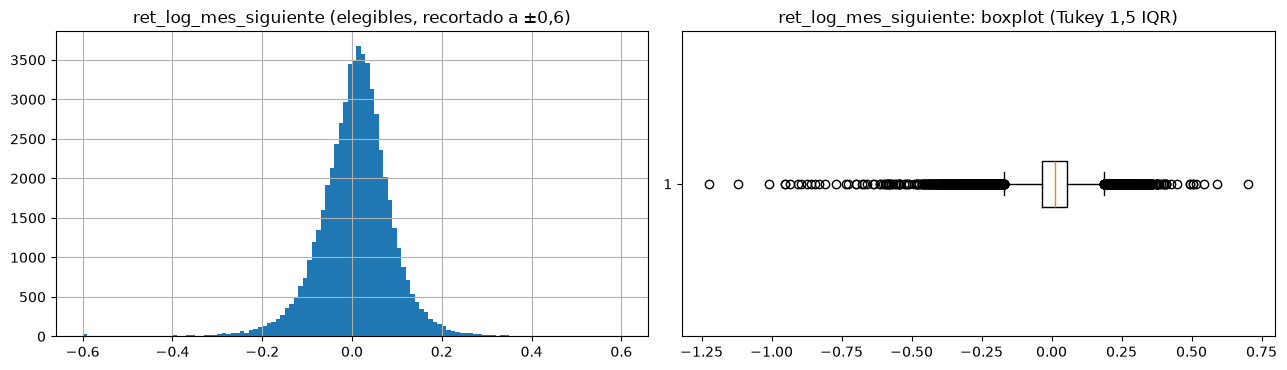

In [13]:
# Atípicos de los predictores y del objetivo en filas elegibles: Tukey IQR (leve 1,5 y extremo 3) y |z| >= 3.
cols_num = [c for c in FEATURES_OBT + [TARGET] if c.upper() in cols_mes]
x = consulta(f"select {', '.join(cols_num)} from OBT.OBT_ACCION_MES where ELEGIBLE")
x = x.apply(pd.to_numeric, errors='coerce')
q = x.quantile([0.25, 0.75]); iqr = q.loc[0.75] - q.loc[0.25]
fuera = lambda k: ((x < q.loc[0.25] - k * iqr) | (x > q.loc[0.75] + k * iqr)).mean() * 100
z = ((x - x.mean()) / x.std()).abs()
atip = pd.DataFrame({'n': x.notna().sum(), 'pct_iqr_leve': fuera(1.5), 'pct_iqr_extremo': fuera(3.0),
                     'pct_z_ge_3': (z >= 3).mean() * 100, 'asimetria': x.skew(), 'curtosis': x.kurt()}).round(3)
display(atip.sort_values('pct_iqr_extremo', ascending=False))
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
x[TARGET].dropna().clip(-0.6, 0.6).hist(bins=120, ax=ax[0]); ax[0].set_title(f'{TARGET} (elegibles, recortado a ±0,6)')
ax[1].boxplot(x[TARGET].dropna(), vert=False, whis=1.5); ax[1].set_title(f'{TARGET}: boxplot (Tukey 1,5 IQR)')
plt.tight_layout(); plt.show()

In [14]:
# OBT_ACCION_DIA, controles de Spark y métricas de CALIDAD.
display(perfil[(perfil.capa == 'OBT') & (perfil.tabla == 'OBT_ACCION_DIA') & ((perfil.faltantes > 0) | (perfil.imputados.fillna(0) > 0))]
        [['columna', 'pct_faltantes', 'pct_faltantes_por_imputacion', 'pct_invalidos', 'pct_atipicos', 'pct_imputados', 'tipo_imputacion']]
        .reset_index(drop=True))
if 'OBT.VALIDACION_OBT' in existentes:
    val = consulta('select * from OBT.VALIDACION_OBT')
    print(f"VALIDACION_OBT: {len(val)} controles, {int((~val.ok.astype(bool)).sum())} fallidos"); display(val)
dq = consulta('select DIMENSION, CAPA, METRICA, VALOR, UNIDAD, DESCRIPCION from CALIDAD.DQ_METRICAS order by DIMENSION, CAPA, METRICA')
display(dq)

,columna,pct_faltantes,pct_faltantes_por_imputacion,pct_invalidos,pct_atipicos,pct_imputados,tipo_imputacion
0,DIF_CIERRE_AJUSTADO,0.0338,NaN,NaN,NaN,0.0,derivada del valor imputado
1,RET_PCT_DIARIO,0.0338,NaN,0.0,NaN,0.0,derivada del valor imputado
2,RET_LOG_DIARIO,0.0338,NaN,NaN,0.0031,0.0,derivada del valor imputado
3,DIF_APERTURA_AJUSTADA,0.0338,NaN,NaN,NaN,0.0,derivada del valor imputado
4,RET_PCT_APERTURA,0.0338,NaN,0.0,NaN,0.0,derivada del valor imputado
5,RET_LOG_APERTURA,0.0338,NaN,NaN,0.0025,0.0,derivada del valor imputado
6,RET_PCT_NOCTURNO,0.0338,NaN,0.0,NaN,0.0,derivada del valor imputado
7,RET_LOG_NOCTURNO,0.0338,NaN,NaN,0.0016,0.0,derivada del valor imputado
8,RET_LOG_SP500,0.0186,NaN,NaN,NaN,NaN,


VALIDACION_OBT: 17 controles, 0 fallidos


,control,esperado,obtenido,ok,ejecutado_en
0,join OBT x dim_accion conserva filas,87178,87178,True,2026-11-18 04:10:07.119033
1,OBT (grano accion x mes): filas = combinacione...,87178,87178,True,2026-11-18 04:10:07.119033
2,OBT tiene una fila por accion y mes cerrado,87178,87178,True,2026-11-18 04:10:07.119033
3,OBT_ACCION_DIA conserva las filas de fct_preci...,1832433,1832433,True,2026-11-18 04:10:07.119033
4,OBT_ACCION_DIA (grano accion x dia): filas = c...,1832433,1832433,True,2026-11-18 04:10:07.119033
5,dim_accion: filas = combinaciones distintas de...,1130,1130,True,2026-11-18 04:10:07.119033
6,dim_fecha: filas = combinaciones distintas de ...,4245,4245,True,2026-11-18 04:10:07.119033
7,fct_mercado_diario: filas = combinaciones dist...,4245,4245,True,2026-11-18 04:10:07.119033
8,fct_precios_diarios: filas = combinaciones dis...,1832433,1832433,True,2026-11-18 04:10:07.119033
9,mercado del mes siguiente solo con meses cerrados,0,0,True,2026-11-18 04:10:07.119033


,dimension,capa,metrica,valor,unidad,descripcion
0,completitud,BRONZE,fotos_composicion_bajo_495_pct,39.468039,%,Fotos de la composicion (desde fecha_inicio) c...
1,completitud,BRONZE,miembros_minimo_por_foto,444.000000,acciones,Menor numero de simbolos en una foto de la com...
2,completitud,BRONZE/SILVER,tickers_sp500_sin_precios_pct,20.936281,%,Acciones que estuvieron en el S&P 500 desde fe...
3,completitud,GOLD,dias_miembro_sin_precio_pct,12.756700,%,Dias bursatiles en que una accion era miembro ...
4,completitud,RAW,filas_cierre_ajustado_nulo_pct,0.000000,%,Filas de RAW.PRECIOS_DIARIOS sin cierre ajustado.
5,completitud,SILVER,acciones_con_hueco_largo,12.000000,acciones,Acciones con al menos un tramo excluido por hu...
6,completitud,SILVER,dias_excluidos_por_hueco_largo,11331.000000,dias,Dias bursatiles dentro de la vida de cada acci...
7,completitud,SILVER,dias_imputados_pct,0.000000,%,Dias bursatiles sin precio valido que se imput...
8,completitud,SILVER,dias_tasa_irx_rellenada_pct,0.047114,%,"Dias bursatiles sin cotizacion de ^IRX, rellen..."
9,consistencia,BRONZE,empresas_con_cambio_de_simbolo,28.000000,empresas,Empresas del historico que cambiaron de simbol...


## 10. Hallazgos

Cada hallazgo sale de los números de arriba (no se escribe a mano): **hallazgo → evidencia → consecuencia**
para el modelado. Si cambian los datos, cambian los hallazgos.

In [15]:
# Hallazgos generados desde los resultados del notebook.
H = []
def agrega(h, e, c): H.append({'hallazgo': h, 'evidencia': e, 'consecuencia': c})
if raw_dup['grupos']:
    agrega('RAW tiene cargas repetidas de la misma (ticker, fecha)',
           f"{int(raw_dup['filas']):,} filas en {int(raw_dup['grupos']):,} claves repetidas; Bronze queda con {int(brz['filas']):,} filas y 0 duplicados",
           'La deduplicacion de Bronze (ultima carga) es necesaria: sin ella los retornos se duplicarian. RAW se mantiene append-only como historial.')
inv_capa = perfil[perfil.regla_invalido != 'no evaluado'].groupby('capa', observed=True).invalidos.sum().astype(int)
despues = perfil[(perfil.capa.isin(['SILVER', 'GOLD', 'OBT'])) & (perfil.invalidos.fillna(0) > 0)]
if len(despues):
    ejemplos = ''
    sim = despues[despues.regla_invalido.str.startswith('simbolo')]
    if len(sim):
        malos = consulta("select TICKER from SILVER.SLV_ACCIONES where TICKER <> UPPER(TICKER) or TICKER like '% %'").ticker.tolist()
        ejemplos = f"; simbolos mal formados en SILVER.SLV_ACCIONES: {malos}"
    agrega('Quedan valores invalidos despues de Silver',
           f"invalidos por capa {inv_capa.to_dict()}; columnas: " + ', '.join(f'{r.capa}.{r.tabla}.{r.columna} ({int(r.invalidos)})' for r in despues.itertuples()) + ejemplos,
           'La regla de Bronze no los filtra: corregir en Bronze (limpiar el simbolo de la fuente o agregar la equivalencia) con su prueba y su antes/despues en migracion_pipeline.md.')
elif inv_capa.sum():
    agrega('Silver elimina los valores invalidos de RAW y Bronze', f"invalidos por capa {inv_capa.to_dict()}",
           'Las capas de modelado no necesitan volver a filtrar por dominio; los invalidos se tratan una sola vez, en Silver.')
else:
    agrega('No hay valores invalidos por regla de dominio en ninguna capa', f"invalidos por capa {inv_capa.to_dict()}",
           'La limpieza por dominio no cambia datos en esta corrida; las reglas quedan como control.')
tot_imp = int(por_anio.imputados.sum()); tot_dias = int(por_anio.dias.sum())
if tot_imp:
    agrega('La imputacion es pequena y acotada',
           f"{tot_imp:,} de {tot_dias:,} dias de Silver imputados ({100 * tot_imp / tot_dias:.3f} %), huecos de hasta {int(largo.largo.max())} dias; "
           f"{int(obt_imp['con_imputados'] or 0):,} filas de la OBT mensual con algun dia imputado ({int(obt_imp['elegibles_con_imputados'] or 0):,} elegibles)",
           'El retorno del dia imputado es 0 y baja un poco la volatilidad de ese mes; dias_imputados_mes permite medirlo o excluir esas filas en el EDA.')
else:
    agrega('No hubo dias imputados en esta corrida', f'0 de {tot_dias:,} dias de Silver',
           'La regla de imputacion (huecos <= 5 dias) no se activo; los huecos, si los hay, son tramos excluidos.')
con_nulos = obt_f[(obt_f.uso == 'predictor') & (obt_f.pct_faltantes_elegibles > 0)].sort_values('pct_faltantes_elegibles', ascending=False)
if len(con_nulos):
    agrega(f'{len(con_nulos)} predictores tienen nulos aun en filas elegibles',
           '; '.join(f'{r.columna} {r.pct_faltantes_elegibles:.2f} % ({r.razon_del_nulo or "revisar"})' for r in con_nulos.head(5).itertuples()),
           'Imputar dentro del Pipeline (mediana ajustada en cada pliegue, src/pipeline.py), nunca antes de dividir; si una columna es casi toda nula, sacarla de los predictores.')
if TARGET in atip.index:
    a = atip.loc[TARGET]
    if a.curtosis > 1 or a.pct_z_ge_3 > 0.27:
        agrega('El objetivo tiene colas mas gruesas que una normal',
               f"curtosis en exceso {a.curtosis:.1f} (normal: 0); {a.pct_z_ge_3:.2f} % con |z| >= 3 (normal: 0,27 %); {a.pct_iqr_extremo:.2f} % fuera de 3 IQR (elegibles)",
               'Preferir metricas robustas (MAE, IC de Spearman) y modelos que no supongan normalidad; no borrar los extremos, que son retornos reales.')
ohlc_slv = inconsistencias.set_index('tabla').loc['SILVER.SLV_PRECIOS_ACCIONES'] if 'SILVER.SLV_PRECIOS_ACCIONES' in set(inconsistencias.tabla) else None
if ohlc_slv is not None and int(ohlc_slv[['maximo_menor_que_minimo', 'cierre_fuera_de_rango', 'apertura_fuera_de_rango']].sum()):
    raw_o = inconsistencias.set_index('tabla').loc['RAW.PRECIOS_DIARIOS'] if 'RAW.PRECIOS_DIARIOS' in set(inconsistencias.tabla) else None
    agrega('Quedan dias con apertura o cierre fuera del rango minimo-maximo',
           f"Silver: maximo < minimo {int(ohlc_slv.maximo_menor_que_minimo)}, cierre fuera {int(ohlc_slv.cierre_fuera_de_rango)}, apertura fuera {int(ohlc_slv.apertura_fuera_de_rango)}"
           + (f"; en RAW (acciones) apertura fuera {int(raw_o.apertura_fuera_de_rango)}" if raw_o is not None else ''),
           'Silver valida maximo >= minimo y marca el cierre fuera de rango, pero no la apertura: son errores de la fuente. Afectan rango_hl y el retorno nocturno de esos dias; marcarlos o excluirlos es una decision del pipeline.')
if int(irx['rellenados'] or 0):
    agrega('La tasa libre de riesgo se rellena algunos dias',
           f"{int(irx['rellenados']):,} de {int(irx['dias']):,} dias con ^IRX rellenada", 'Efecto despreciable en rf_mes; queda marcado en tasa_irx_rellenada.')
hallazgos = pd.DataFrame(H)
with pd.option_context('display.max_colwidth', 200):
    display(hallazgos)

,hallazgo,evidencia,consecuencia
0,"RAW tiene cargas repetidas de la misma (ticker, fecha)","23,276 filas en 4,048 claves repetidas; Bronze queda con 1,845,167 filas y 0 duplicados",La deduplicacion de Bronze (ultima carga) es necesaria: sin ella los retornos se duplicarian. RAW se mantiene append-only como historial.
1,Quedan valores invalidos despues de Silver,"invalidos por capa {'RAW': 563, 'BRONZE': 4, 'SILVER': 2, 'GOLD': 2, 'CALIDAD': 0, 'OBT': 0}; columnas: SILVER.SLV_ACCIONES.TICKER (1), SILVER.SLV_MEMBRESIA_SP500.TICKER (1), GOLD.DIM_ACCION.TICKE...",La regla de Bronze no los filtra: corregir en Bronze (limpiar el simbolo de la fuente o agregar la equivalencia) con su prueba y su antes/despues en migracion_pipeline.md.
2,No hubo dias imputados en esta corrida,"0 de 1,832,433 dias de Silver","La regla de imputacion (huecos <= 5 dias) no se activo; los huecos, si los hay, son tramos excluidos."
3,2 predictores tienen nulos aun en filas elegibles,cambio_rango_log_hl_21_63 0.02 % (ventana de 63 dias: historia corta); volumen_relativo_log_21_252 0.00 % (ventana de 252 dias: historia corta),"Imputar dentro del Pipeline (mediana ajustada en cada pliegue, src/pipeline.py), nunca antes de dividir; si una columna es casi toda nula, sacarla de los predictores."
4,El objetivo tiene colas mas gruesas que una normal,"curtosis en exceso 8.3 (normal: 0); 1.24 % con |z| >= 3 (normal: 0,27 %); 0.51 % fuera de 3 IQR (elegibles)","Preferir metricas robustas (MAE, IC de Spearman) y modelos que no supongan normalidad; no borrar los extremos, que son retornos reales."
5,Quedan dias con apertura o cierre fuera del rango minimo-maximo,"Silver: maximo < minimo 0, cierre fuera 0, apertura fuera 5; en RAW (acciones) apertura fuera 39","Silver valida maximo >= minimo y marca el cierre fuera de rango, pero no la apertura: son errores de la fuente. Afectan rango_hl y el retorno nocturno de esos dias; marcarlos o excluirlos es una d..."
6,La tasa libre de riesgo se rellena algunos dias,"2 de 4,245 dias con ^IRX rellenada",Efecto despreciable en rf_mes; queda marcado en tasa_irx_rellenada.


## 11. Resultados guardados y evidencia de la ejecución

Los resultados se guardan en `docs/calidad/analisis_pipeline/` (CSV) para citarlos en el memo, junto con
el SQL ejecutado. Con el motor DuckDB no se guarda nada, para no mezclar la muestra con los datos reales.

In [16]:
# Guarda perfil, flujo, inconsistencias, imputados, OBT y hallazgos (solo con Snowflake) y resume la ejecucion.
salida = R / 'docs/calidad/analisis_pipeline'
if MOTOR == 'snowflake':
    salida.mkdir(exist_ok=True)
    for nombre, df in {'perfil_columnas_capas': perfil, 'resumen_capas': res.reset_index(), 'linaje_variables': linaje,
                       'flujo_filas': flujo, 'duplicados': pd.DataFrame(dup), 'inconsistencias_ohlc': inconsistencias,
                       'imputados_por_anio': por_anio, 'obt_mes_faltantes': obt_f, 'obt_mes_atipicos': atip.reset_index(names='columna'),
                       'hallazgos': hallazgos}.items():
        df.to_csv(salida / f'{nombre}.csv', index=False)
    (salida / 'ejecucion.json').write_text(json.dumps({
        'motor': MOTOR, 'base': BASE, 'inicio_utc': INICIO.isoformat(), 'fin_utc': datetime.now(timezone.utc).isoformat(),
        'consultas': len(CONSULTAS), 'segundos_en_consultas': round(sum(c['segundos'] for c in CONSULTAS), 1),
        'operacion': 'solo SELECT', 'sql': CONSULTAS}, indent=2, ensure_ascii=False))
    print(f'Guardado en {salida.relative_to(R)}: {sorted(p.name for p in salida.iterdir())}')
else:
    print('Motor DuckDB: no se guardan CSV.')
print(f'{len(CONSULTAS)} consultas SELECT, {sum(c["segundos"] for c in CONSULTAS):.1f} s en la base.')
con.close()

Guardado en docs/calidad/analisis_pipeline: ['duplicados.csv', 'ejecucion.json', 'flujo_filas.csv', 'hallazgos.csv', 'imputados_por_anio.csv', 'inconsistencias_ohlc.csv', 'linaje_variables.csv', 'obt_mes_atipicos.csv', 'obt_mes_faltantes.csv', 'perfil_columnas_capas.csv', 'resumen_capas.csv']
92 consultas SELECT, 23.0 s en la base.
